## Processing Data

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd

In [ ]:
df = pd.read_json("/content/drive/MyDrive/ResumeScannerData/resumes_dataset.jsonl", lines=True)
df.head()

,ResumeID,Category,Name,Email,Phone,Location,Summary,Skills,Experience,Education,Text,Source
0,REAL_0001,Java Developer,Chad Griffin,contact@email.com,94105 555 4321000 10 ...,"City, State",jessica claire montgomery street san francisco...,"Python, SQL, Git, Linux",jessica claire montgomery street san francisco...,Computer Science degree,jessica claire montgomery street san francisco...,ResumeAtlas
1,REAL_0002,Java Developer,Melinda Thomas,contact@email.com,17994568777 2017 2018 20152016 3 ...,"City, State",jared arthur maica java developer 17994568777 ...,"Python, SQL, Git, Linux",jared arthur maica java developer 17994568777 ...,Computer Science degree,jared arthur maica java developer 17994568777 ...,ResumeAtlas
2,REAL_0003,Java Developer,Shannon Mccarthy,contact@email.com,9 555 4321000 94105 8 ...,"City, State",jessica claire 9 resumesampleexamplecom 555 43...,"Python, SQL, Git, Linux",jessica claire 9 resumesampleexamplecom 555 43...,Computer Science degree,jessica claire 9 resumesampleexamplecom 555 43...,ResumeAtlas
3,REAL_0004,Java Developer,Christine Kelley,contact@email.com,9 555 4321000 94105 5 ...,"City, State",jessica claire 9 resumesampleexamplecom 555 43...,"Python, SQL, Git, Linux",jessica claire 9 resumesampleexamplecom 555 43...,Computer Science degree,jessica claire 9 resumesampleexamplecom 555 43...,ResumeAtlas
4,REAL_0005,Java Developer,Karen Holt,contact@email.com,100 10 4321000 ...,"City, State",jessica claire 100 montgomery st 10th floor xx...,"Python, SQL, Git, Linux",jessica claire 100 montgomery st 10th floor xx...,Computer Science degree,jessica claire 100 montgomery st 10th floor xx...,ResumeAtlas


In [ ]:
df.columns

Index(['ResumeID', 'Category', 'Name', 'Email', 'Phone', 'Location', 'Summary',
       'Skills', 'Experience', 'Education', 'Text', 'Source'],
      dtype='object')

In [ ]:
needed_columns = [
    'Category',
    'Summary',
    'Skills',
    'Experience',
    'Education',
    'Text'
]
df = df[[column for column in needed_columns if column in df.columns]]
df.head()

,Category,Summary,Skills,Experience,Education,Text
0,Java Developer,jessica claire montgomery street san francisco...,"Python, SQL, Git, Linux",jessica claire montgomery street san francisco...,Computer Science degree,jessica claire montgomery street san francisco...
1,Java Developer,jared arthur maica java developer 17994568777 ...,"Python, SQL, Git, Linux",jared arthur maica java developer 17994568777 ...,Computer Science degree,jared arthur maica java developer 17994568777 ...
2,Java Developer,jessica claire 9 resumesampleexamplecom 555 43...,"Python, SQL, Git, Linux",jessica claire 9 resumesampleexamplecom 555 43...,Computer Science degree,jessica claire 9 resumesampleexamplecom 555 43...
3,Java Developer,jessica claire 9 resumesampleexamplecom 555 43...,"Python, SQL, Git, Linux",jessica claire 9 resumesampleexamplecom 555 43...,Computer Science degree,jessica claire 9 resumesampleexamplecom 555 43...
4,Java Developer,jessica claire 100 montgomery st 10th floor xx...,"Python, SQL, Git, Linux",jessica claire 100 montgomery st 10th floor xx...,Computer Science degree,jessica claire 100 montgomery st 10th floor xx...


In [ ]:
def merge_resume_fields(row):
    fields = [
        row.get('Summary', ''),
        row.get('Skills', ''),
        row.get('Experience', ''),
        row.get('Education', ''),
        row.get('Text', '')
    ]
    return ' '.join(str(f) for f in fields if pd.notna(f))

df['Resume'] = df.apply(merge_resume_fields, axis=1)
df = df[['Category', 'Resume']]
df.head()

,Category,Resume
0,Java Developer,jessica claire montgomery street san francisco...
1,Java Developer,jared arthur maica java developer 17994568777 ...
2,Java Developer,jessica claire 9 resumesampleexamplecom 555 43...
3,Java Developer,jessica claire 9 resumesampleexamplecom 555 43...
4,Java Developer,jessica claire 100 montgomery st 10th floor xx...


In [ ]:
df["Category"].value_counts()

,count
Category,
Java Developer,200
Python Developer,200
Data Science,200
DevOps,180
SQL Developer,180
Database,150
Testing,150
Web Designing,150
React Developer,150


In [ ]:
categories_to_drop = ["Technical Writer", "Site Reliability Engineer", "Digital Media"]
df = df[~df["Category"].isin(categories_to_drop)]

In [ ]:
df["Category"].value_counts()

,count
Category,
Java Developer,200
Python Developer,200
Data Science,200
DevOps,180
SQL Developer,180
Database,150
Testing,150
Web Designing,150
React Developer,150


In [ ]:
dataset = pd.read_csv("/content/drive/MyDrive/ResumeScannerData/balanced_training_dataset.csv")

In [ ]:
dataset.head()

,Category,Resume
0,Frontend Developer,"As a seasoned , I have a proven track record o..."
1,Backend Developer,With a solid background in Backend Development...
2,Python Developer,"As a , I leverage my expertise in the Python p..."
3,Data Scientist,"With a background in Data Science, I possess a..."
4,Frontend Developer,Experienced with a passion for crafting elegan...


In [ ]:
dataset["Category"].value_counts()

,count
Category,
Frontend Developer,40
Backend Developer,40
Python Developer,40
Data Scientist,40
Full Stack Developer,40
Mobile App Developer (iOS/Android),40
Machine Learning Engineer,40
Cloud Engineer,40
Web Designing,40


In [ ]:
final_dataset = pd.concat([df, dataset], ignore_index=True)
final_dataset

,Category,Resume
0,Java Developer,jessica claire montgomery street san francisco...
1,Java Developer,jared arthur maica java developer 17994568777 ...
2,Java Developer,jessica claire 9 resumesampleexamplecom 555 43...
3,Java Developer,jessica claire 9 resumesampleexamplecom 555 43...
4,Java Developer,jessica claire 100 montgomery st 10th floor xx...
...,...,...
4089,Testing,EXPERIENCE: 1. Principal QA Test Analyst | Ver...
4090,Testing,Professional Background: Thorough Junior Softw...
4091,Testing,"TECHNICAL SKILLS: Manual , Functional , Regres..."
4092,Testing,SUMMARY: Thorough Software QA & Manual Test En...


In [ ]:
print("Duplicates found:", final_dataset['Resume'].duplicated().sum())

Duplicates found: 194


In [ ]:
final_dataset = final_dataset.drop_duplicates(subset=['Resume']).reset_index(drop=True)

In [ ]:
print("Duplicates found:", final_dataset['Resume'].duplicated().sum())

Duplicates found: 0


In [ ]:
final_dataset["Category"].value_counts()

,count
Category,
Java Developer,225
Python Developer,225
Data Science,188
Testing,188
Web Designing,184
Business Analyst,183
SQL Developer,169
Database,167
DevOps,164


In [ ]:
category_map = {
    "DevOps": "DevOps Engineer",
    "DevOps Engineer": "DevOps Engineer",

    "Mobile Developer": "Mobile App Developer",
    "Mobile App Developer (iOS/Android)": "Mobile App Developer",

    "Testing": "QA / Testing Engineer",
    "QA Engineer": "QA / Testing Engineer",
    "Automation Testing": "QA / Testing Engineer",

    "Database": "Database Administrator",
    "Database Administrator": "Database Administrator",

    "Web Designing": "UI/UX & Web Designer",
    "UI/UX Designer": "UI/UX & Web Designer",

    "Frontend Developer": "Frontend Developer",
    "React Developer": "Frontend Developer",

    "Blockchain": "Blockchain Developer",
    "Blockchain Developer": "Blockchain Developer",

    "Network Security Engineer": "Cybersecurity / Network Security",
    "Cybersecurity Analyst": "Cybersecurity / Network Security",

    "Technical Lead": "Engineering Leadership",
    "Engineering Manager": "Engineering Leadership",
    "Principal Engineer": "Engineering Leadership",

    "Software Developer": "Full Stack / Software Developer",
    "Full Stack Developer": "Full Stack / Software Developer",

    "Data Science": "Data Scientist"
}

final_dataset['Category'] = final_dataset['Category'].replace(category_map)

In [ ]:
final_dataset["Category"].value_counts()

,count
Category,
QA / Testing Engineer,289
Full Stack / Software Developer,276
UI/UX & Web Designer,235
Data Scientist,228
Python Developer,225
Java Developer,225
Cybersecurity / Network Security,223
Database Administrator,223
Frontend Developer,220


In [ ]:
final_dataset.to_csv("/content/drive/MyDrive/ResumeScannerData/final_dataset.csv", index=False)

## Model Training

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd
import re

In [ ]:
final_dataset = pd.read_csv("/content/drive/MyDrive/ResumeScannerData/final_dataset.csv")

In [ ]:
# remove job titles from the dataset's resume so the model cannot cheat
def remove_job_title(row):
    text = str(row['Resume'])
    category = str(row['Category']).strip()

    # Remove the exact category name case-insensitively
    text = re.sub(re.escape(category), "", text, flags=re.IGNORECASE)

    # Clean up any double spaces or leading/trailing spaces left behind by the deletion
    text = re.sub(r'\s+', ' ', text).strip()

    return text

final_dataset["Resume"] = final_dataset.apply(remove_job_title, axis=1)

In [ ]:
final_dataset.head()

,Category,Resume
0,Java Developer,jessica claire montgomery street san francisco...
1,Java Developer,jared arthur maica 17994568777 linkedincominja...
2,Java Developer,jessica claire 9 resumesampleexamplecom 555 43...
3,Java Developer,jessica claire 9 resumesampleexamplecom 555 43...
4,Java Developer,jessica claire 100 montgomery st 10th floor xx...


In [ ]:
final_dataset["Category"].value_counts()

,count
Category,
QA / Testing Engineer,289
Full Stack / Software Developer,276
UI/UX & Web Designer,235
Data Scientist,228
Python Developer,225
Java Developer,225
Cybersecurity / Network Security,223
Database Administrator,223
Frontend Developer,220


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

X = final_dataset["Resume"]
y = le.fit_transform(final_dataset["Category"])

In [ ]:
X

,Resume
0,jessica claire montgomery street san francisco...
1,jared arthur maica 17994568777 linkedincominja...
2,jessica claire 9 resumesampleexamplecom 555 43...
3,jessica claire 9 resumesampleexamplecom 555 43...
4,jessica claire 100 montgomery st 10th floor xx...
...,...
3895,EXPERIENCE: 1. Principal QA Test Analyst | Ver...
3896,Professional Background: Thorough Junior Softw...
3897,"TECHNICAL SKILLS: Manual , Functional , Regres..."
3898,SUMMARY: Thorough Software QA & Manual Test En...


In [ ]:
y

array([14, 14, 14, ..., 19, 19, 19])

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_val_test, y_train, y_val_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
X_val, X_test, y_val, y_test = train_test_split(X_val_test, y_val_test, test_size=0.5, random_state=42, stratify=y_val_test)

In [ ]:
num_classes = len(le.classes_)
print(num_classes)

24


In [ ]:
from sentence_transformers import SentenceTransformer
embedder1 = SentenceTransformer("anass1209/resume-job-matcher-all-MiniLM-L6-v2")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [ ]:
embedder2 = SentenceTransformer("BAAI/bge-base-en-v1.5")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
embedder3 = SentenceTransformer("BAAI/bge-large-en-v1.5")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/779 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

In [ ]:
X_train_emb = embedder2.encode(X_train.tolist(), show_progress_bar=True)
X_val_emb = embedder2.encode(X_val.tolist(), show_progress_bar=True)
X_test_emb = embedder2.encode(X_test.tolist(), show_progress_bar=True)

Batches:   0%|          | 0/98 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

In [ ]:
X_train_emb.shape, X_train_emb[0].shape

((3120, 768), (768,))

In [ ]:
inputs = tf.keras.Input(shape=X_train_emb[0].shape, name="minilm_embeddings")

x = tf.keras.layers.Dense(128, activation="relu")(inputs)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.4)(x)

x = tf.keras.layers.Dense(64, activation="relu")(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(num_classes, activation="softmax", name="job_role_probabilities")(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs, name="ResumeClassifier")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "ResumeClassifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ minilm_embeddings (InputLayer)  │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 128)            │        98,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ job_role_probabilities (Dense)  │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,016 (425.84 KB)

 Trainable params: 108,632 (424.34 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    X_train_emb,
    y_train,
    validation_data=(X_val_emb, y_val),
    epochs=30,
    batch_size=64,
    callbacks=callbacks
)

Epoch 1/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.5131 - loss: 1.7428 - val_accuracy: 0.3359 - val_loss: 2.6240 - learning_rate: 0.0050
Epoch 2/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7545 - loss: 0.8521 - val_accuracy: 0.5436 - val_loss: 2.1736 - learning_rate: 0.0050
Epoch 3/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7987 - loss: 0.6578 - val_accuracy: 0.7128 - val_loss: 1.6919 - learning_rate: 0.0050
Epoch 4/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8324 - loss: 0.5762 - val_accuracy: 0.7487 - val_loss: 1.2832 - learning_rate: 0.0050
Epoch 5/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8356 - loss: 0.5112 - val_accuracy: 0.7872 - val_loss: 0.9487 - learning_rate: 0.0050
Epoch 6/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8500 - loss: 0.4887 - val_accuracy: 0.7667 - val_loss: 0.9198 - learning_rate: 0.0050
Epoch 7/30
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8561 - loss: 0.4468 - val_accuracy:

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.12/dist-packages/matplotlib/pyplot.py'>

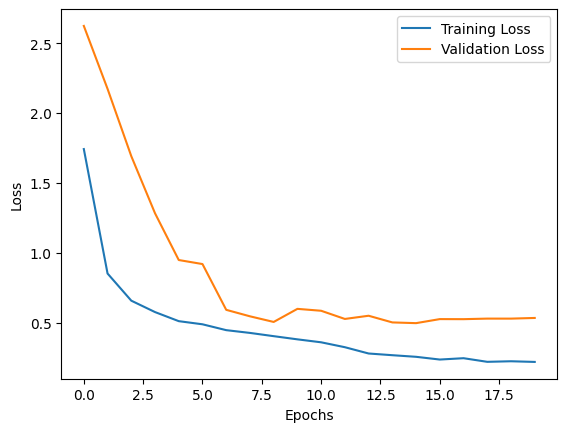

In [ ]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt

In [ ]:
model.evaluate(X_test_emb, y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8846 - loss: 0.5061  


[0.5060760378837585, 0.8846153616905212]

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


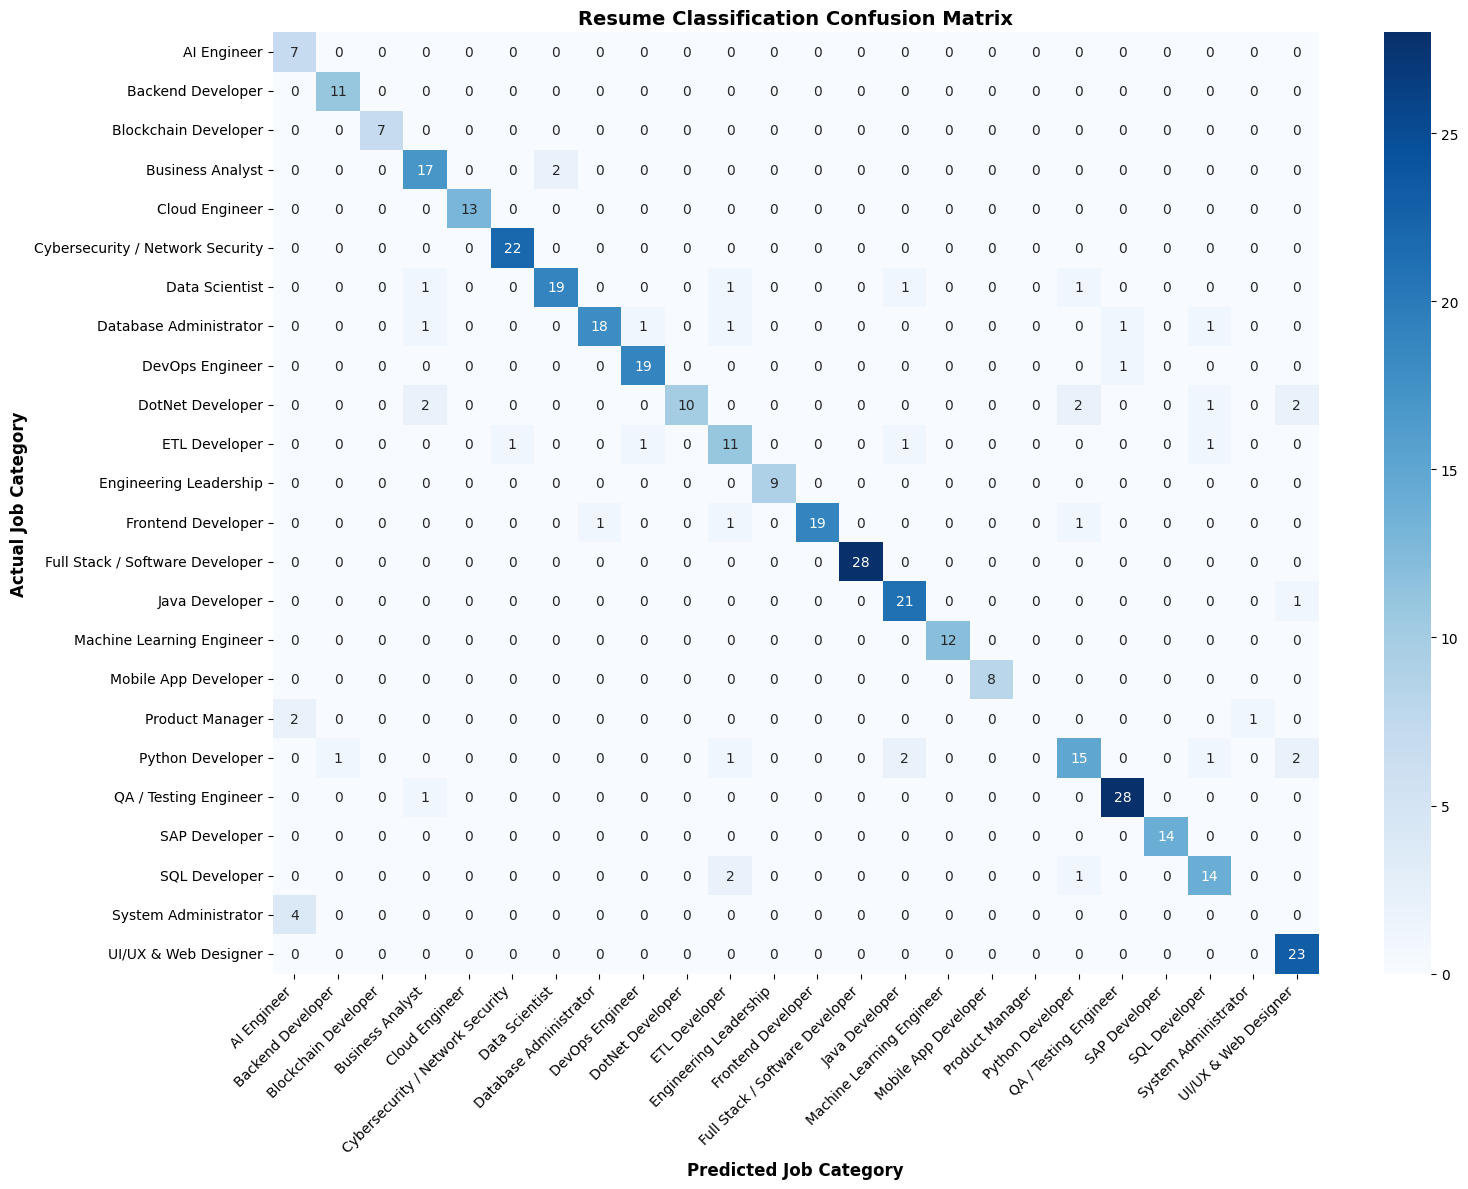


--- Detailed Classification Report ---
                                  precision    recall  f1-score   support

                     AI Engineer       0.54      1.00      0.70         7
               Backend Developer       0.92      1.00      0.96        11
            Blockchain Developer       1.00      1.00      1.00         7
                Business Analyst       0.77      0.89      0.83        19
                  Cloud Engineer       1.00      1.00      1.00        13
Cybersecurity / Network Security       0.96      1.00      0.98        22
                  Data Scientist       0.90      0.83      0.86        23
          Database Administrator       0.95      0.78      0.86        23
                 DevOps Engineer       0.90      0.95      0.93        20
                DotNet Developer       1.00      0.59      0.74        17
                   ETL Developer       0.65      0.73      0.69        15
          Engineering Leadership       1.00      1.00      1.00        

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Get predicted class indices
y_pred_probs = model.predict(X_test_emb)
y_pred = np.argmax(y_pred_probs, axis=1)

# 2. Extract actual string class names in correct order
# le.classes_ contains class names ordered by their integer index (0, 1, 2...)
class_names = le.classes_

# 3. Compute Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# 4. Plot Heatmap with Category Names
plt.figure(figsize=(16, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)

plt.xlabel("Predicted Job Category", fontsize=12, fontweight="bold")
plt.ylabel("Actual Job Category", fontsize=12, fontweight="bold")
plt.title("Resume Classification Confusion Matrix", fontsize=14, fontweight="bold")

# Rotate tick labels for scannability
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

# 5. Optional: Print Classification Report with Class Names
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred, target_names=class_names))

In [ ]:
resume = ["Header & ContactName: Alex SmithTitle: Backend Software EngineerLocation: Habra, West Bengal, IndiaPhone: +91 98765 43210Email: alex.smith@email.comLinks: LinkedIn Profile | GitHub ProfileProfessional SummaryResults-driven Backend Developer with 4+ years of experience building scalable microservices, high-performance REST APIs, and optimized database architectures.Expert in Java, Node.js, and Python alongside cloud deployments on AWS.Proven track record of reducing API latency by 45% and managing high-volume data transactions.Technical SkillsLanguages: Java, Python, JavaScript (Node.js), SQLFrameworks: Spring Boot, Express.js, DjangoDatabases & Caching: PostgreSQL, MySQL, MongoDB, RedisTools & Cloud: Docker, Git, AWS, CI/CD pipelinesProfessional ExperienceBackend Developer | 2023–PresentTechCorp Solutions | Kolkata, West BengalArchitected and deployed microservices using Spring Boot, increasing platform resilience by 35%.Optimized complex SQL queries and index structures, improving database response speeds by 30%.Integrated Redis caching layers to reduce core server load during peak traffic events.Junior Backend Developer | 2021–2023WebCraft Tech | RemoteDesigned and documented RESTful APIs utilized by cross-platform mobile and web frontend teams.Automated testing and deployment scripts with Docker and basic CI/CD pipelines.EducationBachelor of Technology (B.Tech) in Computer ScienceMAKAUT | West Bengal, IndiaGraduation Year: 2021",
          "Contact InformationName: Alex SmithEmail: alex.smith@email.com | Phone: (555) 019-2834Location: New York, NY | LinkedIn: linkedin.com | GitHub: github.comProfessional SummaryAnalytical Data Scientist with 4 years of experience building machine learning models, running A/B tests, and turning complex datasets into clear business growth. Skilled in Python, SQL, and data visualization.Technical SkillsProgramming Languages: Python, R, SQLLibraries & Frameworks: Pandas, Scikit-Learn, TensorFlow, PyTorchTools & Platforms: Tableau, Git, AWS, JupyterCore Concepts: Predictive Modeling, A/B Testing, Statistical AnalysisProfessional ExperienceData Scientist | DataCorp (June 2024 – Present)Built a machine learning model to predict customer churn, increasing user retention by 15%.Designed an A/B testing framework that cut experimental cycle time by 25%.Automated weekly data reports using Python scripts, saving 10 hours of manual work every week.Junior Data Analyst | TechStart Solutions (August 2022 – May 2024)Cleared and processed large datasets using SQL and Pandas to find key sales trends.Created interactive dashboards in Tableau to help company leaders track daily performance metrics.EducationBachelor of Science in Statistics | State University (Graduated May 2022)"]
new_emb = embedder2.encode(resume)

probabilities1 = model.predict(new_emb)[0]
probabilities2 = model.predict(new_emb)[1]

predicted_class_idx1 = np.argmax(probabilities1)
predicted_role1 = le.inverse_transform([predicted_class_idx1])[0]
confidence1 = probabilities1[predicted_class_idx1] * 100

predicted_class_idx2 = np.argmax(probabilities2)
predicted_role2 = le.inverse_transform([predicted_class_idx2])[0]
confidence2 = probabilities2[predicted_class_idx2] * 100

print(f"Predicted Role: {predicted_role1} ({confidence1:.2f}% match)")
print(f"Predicted Role: {predicted_role2} ({confidence2:.2f}% match)")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 503ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
Predicted Role: Backend Developer (99.68% match)
Predicted Role: Data Scientist (94.24% match)


In [ ]:
def predict_jobrole(resume, top_k=5):
    # Generate embedding
    new_emb = embedder2.encode(resume)

    # Get prediction probabilities
    probabilities = model.predict(new_emb, verbose=0)[0]

    # Get indices of top-k predictions (highest probabilities first)
    top_indices = np.argsort(probabilities)[::-1][:top_k]

    print("Top Predictions:\n")

    for rank, idx in enumerate(top_indices, start=1):
        role = le.inverse_transform([idx])[0]
        confidence = probabilities[idx] * 100
        print(f"{rank}. {role:<35} {confidence:.2f}%")

In [ ]:
resume_example_1 = """
  Contact InformationName: Alex SmithPhone: +1 (555) 019-2834Email: alex.smith@email.comLocation: City, StateLinkedIn / Portfolio: linkedin.com
  Professional SummaryDetail-oriented Software Test Engineer with over 4 years of experience in manual and automated testing.Skilled in building test automation frameworks, reducing testing cycles, and tracking defects.Strong background in Agile environments collaborating with developers to ensure high-quality software releases.
  Technical SkillsTesting Types: Functional Testing, Regression Testing, Smoke Testing, Integration Testing, API TestingAutomation & Tools: Selenium WebDriver, TestNG, Postman, Maven, JUnitLanguages: Java, Python, SQLManagement & CI/CD: JIRA, Confluence, Jenkins, Git
  Work ExperienceSoftware Test EngineerQuality Tech Solutions | June 2023 – PresentDesigned and executed over 150 comprehensive test cases, cutting manual testing efforts by 40% using Selenium and TestNG.Logged and tracked software defects using JIRA, decreasing resolution time by 25%.Performed API testing and validated database integrity using SQL queries.Participated in daily Agile standups and sprint planning with developers and product managers
  Junior QA TesterDataSoft Systems | August 2021 – May 2023Executed functional, smoke, and regression test suites for web and mobile applications.Identified and documented critical bugs, improving overall application stability and user experience.Maintained detailed test documentation and reported weekly progress metrics.
  EducationBachelor of Science in Computer ScienceState University | Graduated May 2021CertificationsISTQB Certified Tester Foundation Level (CTFL)
"""

predict_jobrole(resume = [resume_example_1])

Top Predictions:

1. QA / Testing Engineer               99.96%
2. ETL Developer                       0.01%
3. Cybersecurity / Network Security    0.01%
4. Python Developer                    0.00%
5. Data Scientist                      0.00%


In [ ]:
resume_example_2= """
Resume

Name: Alex Morgan

Professional Summary

Software Engineer with 3 years of experience designing and developing scalable applications. Experienced in building REST APIs, integrating machine learning models into production systems, and deploying cloud-native applications. Passionate about solving business problems using data-driven approaches and modern software engineering practices.

Technical Skills

Programming Languages

Python
Java
SQL
JavaScript
Bash
Frameworks

FastAPI
Flask
TensorFlow
Scikit-learn
React
Node.js
Express

Cloud & DevOps

AWS EC2
AWS S3
Docker
GitHub Actions
Kubernetes (basic)
Nginx

Databases

PostgreSQL
MongoDB
Redis

Machine Learning

Feature Engineering
NLP
Classification
Model Evaluation
Embedding Models
Transformers
Pandas
NumPy

Experience
Software Engineer

TechNova Solutions

2023 – Present

Developed REST APIs using FastAPI and Python.
Built a customer support ticket classification system using Sentence Transformers.
Improved model inference latency by 35%.
Created data preprocessing pipelines for millions of records.
Deployed ML services using Docker and AWS.
Designed database schemas in PostgreSQL.
Collaborated with frontend developers to integrate prediction APIs.
Implemented CI/CD pipelines using GitHub Actions.
Junior Software Developer

Innovate Labs

2022 – 2023

Built internal web dashboards using React.
Developed backend APIs with Flask.
Automated report generation using Python.
Wrote SQL queries for analytical reports.
Assisted data scientists in feature engineering and model deployment.
Projects

Resume Role Prediction System

Built a resume classifier using transformer embeddings.
Fine-tuned a neural network classifier.
Achieved 91% validation accuracy.

Customer Churn Prediction

Built classification models using XGBoost and Random Forest.
Performed feature engineering.
Conducted SHAP explainability analysis.

Semantic Search Engine

Used Sentence Transformers.
Implemented vector similarity search.
Indexed over 500,000 documents.
Education

Bachelor of Technology in Computer Science

Certifications
AWS Cloud Practitioner
TensorFlow Developer Certificate
"""

In [ ]:
predict_jobrole([resume_example_2])

Top Predictions:

1. Python Developer                    51.27%
2. Cloud Engineer                      22.71%
3. DotNet Developer                    6.17%
4. DevOps Engineer                     4.90%
5. Backend Developer                   3.96%


In [ ]:
resume_example_3 = """
Contact InformationName: Alex JordanPhone: +1 (555) 019-2834 | Email: alex.jordan@email.comLocation: San Francisco, CA (Open to Remote)Links: GitHub Profile | LinkedIn Profile | Portfolio WebsiteProfessional SummaryMachine Learning Engineer with 4+ years of experience designing, training, and deploying production machine learning systems. Specialized in deep learning, natural language processing (NLP), and scalable model deployment using PyTorch and AWS. Proven track record of optimizing model inference time and driving tangible business metrics.
Technical SkillsProgramming Languages: Python, SQL, C++, ScalaML/DL Frameworks: PyTorch, TensorFlow, Scikit-learn, Hugging Face TransformersMLOps & Deployment: Docker, Kubernetes, AWS SageMaker, MLflow, CI/CD pipelinesBig Data & Tools: Apache Spark, Airflow, Git, Linux/UnixProfessional ExperienceMachine Learning Engineer | DataTech Solutions (June 2024 – Present)Architected end-to-end deep learning recommendation pipelines serving 2M+ daily active users.Reduced model inference latency by 45% utilizing ONNX runtime optimization and model quantization.Integrated continuous model monitoring via MLflow and Prometheus to detect data drift, improving production uptime to 99.8%.
Collaborated with data engineering and product teams to ingest 500GB of daily user data into real-time feature stores.Junior ML Engineer | InnoAI Labs (August 2022 – May 2024)Developed text-classification and sentiment analysis models using BERT and PyTorch, increasing text categorization accuracy from 76% to 89%.Containerized machine learning training scripts using Docker and deployed scalable microservice endpoints on AWS ECS.Automated data preprocessing pipelines using Apache Airflow, reducing manual data cleaning time by 60%.EducationMaster of Science in Computer Science (Specialization in Machine Learning)University of California, Berkeley (Graduated: May 2022)Bachelor of Science in Statistics and Data ScienceUniversity of California, Los Angeles (Graduated: May 2020)
"""

predict_jobrole([resume_example_3])

Top Predictions:

1. Machine Learning Engineer           93.68%
2. Python Developer                    4.68%
3. Data Scientist                      1.60%
4. Cybersecurity / Network Security    0.01%
5. Engineering Leadership              0.01%


In [ ]:
resume_example_4 = """
SUMMARY
Analytical and results-driven professional with over 4 years of experience extracting actionable insights from large datasets. Adept at building predictive models, optimizing algorithms, and deploying statistical solutions to solve complex business problems. Proven track record of collaborating with cross-functional teams to drive data-informed decision-making.

SKILLS
Programming: Python (Pandas, NumPy, Scikit-Learn, TensorFlow, PyTorch), R, SQL, Bash
Tools & Platforms: Docker, Git, AWS (S3, EC2, SageMaker), Jupyter, Apache Spark, MLflow
Techniques: A/B Testing, Natural Language Processing (NLP), Time Series Forecasting, Regression, Clustering, XGBoost, Deep Learning, Data Visualization (Tableau, Matplotlib)

PROFESSIONAL EXPERIENCE
Senior Data Analyst | TechCorp Inc. | San Francisco, CA | 2022 - Present
- Engineered robust ETL pipelines to process 50GB+ of daily user telemetry data using Python and Apache Spark, reducing data processing time by 30%.
- Developed a customer churn prediction model using Random Forest and XGBoost, achieving an F1-score of 0.88 and saving the company an estimated $120k annually.
- Designed and deployed an NLP-based sentiment analysis tool using Hugging Face transformers to analyze customer support tickets.
- Created interactive Tableau dashboards for the executive team to monitor key performance indicators in real-time.

Statistical Modeler | DataSolutions LLC | Austin, TX | 2020 - 2022
- Conducted rigorous A/B testing for e-commerce web features, increasing conversion rates by 4.5%.
- Wrote complex SQL queries to extract and clean unstructured data from relational databases (PostgreSQL) and NoSQL stores (MongoDB).
- Built a time-series forecasting model using ARIMA to predict quarterly sales with 92% accuracy.

EDUCATION
Master of Science in Computer Science (Focus on Artificial Intelligence)
University of Texas at Austin | 2018 - 2020

Bachelor of Science in Mathematics
University of California, Berkeley | 2014 - 2018
"""

predict_jobrole([resume_example_4])

Top Predictions:

1. Data Scientist                      99.75%
2. Python Developer                    0.11%
3. ETL Developer                       0.08%
4. Machine Learning Engineer           0.04%
5. Business Analyst                    0.02%


In [ ]:
resume_example_5 = """
  SUMMARY
Experienced with Ruby on Rails and JavaScript based programming and a background in IT Technician, Professional Scrum Master, and SDET/QA Automation. Possess strong skills in adaptability, detail oriented, management/leadership, and communication that helps drive the environment towards quality results at a consistent pace.

TECHNICAL SKILLS
Backend: Java, Ruby on Rails (as a full-stack and API-only framework), Rake and Sinatra, Test-Writing (RSpec framework for Ruby), SQL & PostgreSQL.
Frontend: C, C++, Python, JavaScript (ES5/ES6), JavaScript eXtension (JSX), Vue.js, Node.js, React, Redux, Test-Writing (Jest/Enzyme for React.js), HTML & CSS.

TECHNICAL PROJECTS
Review It All
A review platform where users can post and manage reviews.
- Utilized Rails as an API for Backend.
- Applied React Redux/Redux Thunk on Frontend.
- Created a Dark Mode toggle switch built from scratch to switch themes/styling.
- Added a back to top button built from scratch for UI/UX design.

FlatNote
FlatNote is a basic note-taking web application.
- Utilized Rails as an API for Backend.
- Applied React Redux/Redux Thunk on Frontend.
- Implemented React Semantic UI for Styling/CSS.

Camelike
Camelike is a Rails microblogging web application.
- Built using Ruby on Rails as a Full-Stack application without external frontend libraries.
- Took advantage of using Bulma as a framework for CSS.
- Used BCrypt for encryption and secure session management.

EXPERIENCE
Software Engineering Teaching Assistant & Mentor
- Engaged within the classroom by sitting with students, working alongside them, and spending time working with them outside of class hours.
- Helped enhance student code reviews and portfolio projects leading them to build production-grade web applications.

SDET / QA Automation Engineer
- Wrote automated test scripts and conducted system-wide requirement analysis.
- Conducted module-level work effort estimations and integrated test plans across microservices.
"""

resume_example_6 = """
  PROFESSIONAL SUMMARY
Dedicated engineer with a strong technical background and extensive expertise in a wide range of programming languages, frameworks, and cloud technologies. Known for providing strategic leadership in architectural design and implementation, emphasizing code quality and performance. Adept at optimizing systems and processes to enhance efficiency and reduce operational costs.

WORK EXPERIENCE
Rewards Management Team - Cloud Engineer
- Collaborated on improving existing on-prem applications as part of a cloud migration project using Java, Kafka, RDS, Spinnaker, Terraform, and EKS.
- Worked on a project integrating a new database backend, providing guidance on the architecture and technical limitations of the stack using Java, Spring, Python, RDS, Kafka, Avro, and ECS.
- Provided feedback and monitoring on Agile processes, support, code standards, and technical design using Docker-compose, Kubernetes, and Datadog.

Servicing Team - Lead Developer
- Enhanced and expanded the payment and invoice tracking system.
- Led design discussions and provided guidance on changes on multiple projects dealing with invoice payment pipelines using Adyen, Kotlin, Ktor, Kotest, Gradle, Testcontainers, and Kubernetes.
- Actively engaged in and made contributions to microservices architecture using TypeScript, Kafka, Yarn, Express, Docker, Docker-Compose, and Kubernetes.

Backend Product Developer
- Worked on backend core products using Java, Spring, Protocol Buffers, REST APIs, JUnit, Selenium, and Gradle.
- Focused on web services delivering customer data queried from NoSQL databases using JavaScript, Backbone, Marionette, Restlet, Spring, Spring MVC, and Marklogic.
- Developed cloud solutions utilizing Coffeescript, JavaScript, Node, SCSS, AWS, EC2, S3, DynamoDB, and SQS.
"""

In [ ]:
predict_jobrole([resume_example_5])

Top Predictions:

1. Full Stack / Software Developer     76.36%
2. Frontend Developer                  17.55%
3. UI/UX & Web Designer                4.62%
4. Python Developer                    0.90%
5. Blockchain Developer                0.24%


In [ ]:
predict_jobrole([resume_example_6])

Top Predictions:

1. Backend Developer                   91.82%
2. Cloud Engineer                      7.16%
3. Java Developer                      0.66%
4. Mobile App Developer                0.10%
5. DevOps Engineer                     0.10%


In [ ]:
resume_example_challange = """
  SUMMARY
Versatile software engineer with 5 years of experience architecting end-to-end web applications and integrating machine learning capabilities. Passionate about bridging the gap between complex AI models and user-friendly interfaces, backed by robust database architectures and scalable APIs.

SKILLS
Languages: Python, JavaScript, TypeScript, SQL
Frontend: React, Next.js, Tailwind CSS, Redux
Backend: FastAPI, Node.js, Express, Django
Database & Cloud: PostgreSQL, MongoDB, Redis, AWS (EC2, S3), Pinecone (Vector DB)
AI/ML: PyTorch, Scikit-Learn, Hugging Face Transformers, LangChain, NLP

EXPERIENCE
Software Engineer | InnovateAI Solutions | 2022 - Present
- Architected and deployed a full-stack document analysis SaaS, utilizing React for the frontend and FastAPI for the backend.
- Integrated Hugging Face transformer models to summarize and extract entities from uploaded PDFs, reducing manual review time by 60%.
- Designed and optimized complex PostgreSQL schemas to store user metadata, while utilizing Pinecone vector databases for semantic search functionalities.
- Built responsive, accessible UI components using Tailwind CSS and managed complex application state with Redux.

Data & Backend Developer | DataSync Inc. | 2019 - 2022
- Developed highly scalable REST APIs using Node.js and Express to serve data to web and mobile clients.
- Created automated data pipelines in Python to clean and preprocess 100GB+ of daily raw data for downstream machine learning tasks.
- Improved database query performance by 40% through strategic indexing and rewriting legacy SQL queries.
- Collaborated closely with data scientists to deploy predictive models into production environments using Docker and AWS.

EDUCATION
B.S. in Computer Science
Tech University | 2015 - 2019
"""

predict_jobrole([resume_example_challange])

Top Predictions:

1. Full Stack / Software Developer     76.20%
2. Machine Learning Engineer           14.49%
3. Python Developer                    5.49%
4. Backend Developer                   2.95%
5. Cloud Engineer                      0.23%


In [ ]:
resume_example_7 = """
SUMMARY
AI & Autonomous Systems Specialist with over 3 years of experience developing, training, and deploying deep learning models in production environments. Expertise in computer vision pipelines, LLM agent integration, custom neural architectures, and edge deployment. Proven track record of taking complex raw datasets and building end-to-end inference pipelines served via REST APIs.

TECHNICAL SKILLS
Languages: Python, C++, SQL, Bash
ML Frameworks: PyTorch, TensorFlow, Hugging Face, Scikit-Learn, OpenCV, LangChain, PEFT
MLOps & Infrastructure: Docker, Kubernetes, AWS (SageMaker, S3, EC2), MLflow, DVC, WandB
Databases: PostgreSQL, Pinecone, Redis, MongoDB

WORK EXPERIENCE
AI Solutions Developer | Robotics & Automation Tech | 2024 - Present
- Fine-tuned YOLOv8 object detection models for real-time edge processing on embedded systems with 94.2% mAP.
- Built custom RAG pipeline and fine-tuned open-source LLMs using PEFT/LoRA to generate domain-specific code snippets.
- Designed and served high-throughput model prediction endpoints using FastAPI and Docker on AWS EC2.
- Established automated data version control (DVC) and experiment tracking with WandB across 15+ model iterations.

Junior Research Fellow | Institute of Information Technology | 2022 - 2024
- Researched novel graph neural network (GNN) architectures for predictive modeling on sparse unstructured datasets.
- Optimized deep learning inference latency by 40% using TensorRT quantization for deployment.
- Developed Python ETL workflows to preprocess and augment multi-modal image and text data pipelines.

EDUCATION
M.Tech in Computer Science and Engineering | 2023
B.S. in Computer Science | 2021
"""

resume_example_8 = """
PROFESSIONAL SUMMARY
5 years of industry experience specializing in scalable machine learning infrastructure, model optimization, and production platform engineering. Hands-on experience in training deep learning models, building feature stores, and running distributed PyTorch training jobs across cloud infrastructure.

CORE COMPETENCIES
Machine Learning: PyTorch, TensorFlow, Keras, HuggingFace, XGBoost, Scikit-Learn, Ray, PEFT
Infrastructure & Cloud: Kubernetes, Docker, Terraform, AWS (SageMaker, Lambda, Batch, S3), CircleCI
Data & Distributed Computing: PySpark, MLlib, PostgreSQL, Redis, Kafka, DVC

EXPERIENCE
Production Systems Developer | Cloud Enterprise Corp | 2022 - Present
- Architected and maintained scalable model training and evaluation pipelines on AWS SageMaker for real-time recommendation systems.
- Implemented PySpark distributed feature extraction pipelines processing multi-terabyte log datasets.
- Configured CI/CD automation pipelines using GitHub Actions, Docker, and Kubernetes to deploy model microservices zero-downtime.
- Monitored live model drift and latency metrics in Grafana/Datadog, establishing automated retraining triggers.

Applied AI Specialist | Financial Automation | 2020 - 2022
- Developed document classification and entity extraction models using Transformer architectures (BERT, RoBERTa).
- Reduced model storage size and memory footprint by 60% through post-training weight quantization and pruning.
- Implemented feature vector similarity search using Redis and Pinecone vector database integrations.

CERTIFICATIONS
- Deep Learning Specialization (Coursera / DeepLearning.AI)
- AWS Certified Machine Learning - Specialty
"""

In [ ]:
predict_jobrole([resume_example_7])

Top Predictions:

1. Machine Learning Engineer           100.00%
2. Cloud Engineer                      0.00%
3. Python Developer                    0.00%
4. Data Scientist                      0.00%
5. Engineering Leadership              0.00%


In [ ]:
predict_jobrole([resume_example_8])

Top Predictions:

1. Machine Learning Engineer           99.98%
2. Python Developer                    0.01%
3. Data Scientist                      0.01%
4. Cloud Engineer                      0.00%
5. Blockchain Developer                0.00%


In [ ]:
import os
import joblib

# Create export directory
export_dir = "./exported_model"
os.makedirs(export_dir, exist_ok=True)

# 1. Save Keras Neural Network weights & architecture
model.save(os.path.join(export_dir, "resume_classifier.keras"))

# 2. Save Label Encoder (maps 0, 1, 2... -> "Backend Developer", etc.)
joblib.dump(le, os.path.join(export_dir, "label_encoder.joblib"))

# 3. Save Embedder locally (Optional, but ensures fast offline loading)
# Note: You can also just load "your-768-dim-model-name" directly in FastAPI
embedder2.save_pretrained(os.path.join(export_dir, "embedder"))

print(f"All assets successfully saved to '{export_dir}'!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

All assets successfully saved to './exported_model'!


In [ ]:
import shutil
from google.colab import files

# 1. Zip the exported_model directory
shutil.make_archive("exported_model", "zip", "./exported_model")

# 2. Download the zip file directly to your PC
files.download("exported_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>